# 01 — Exploratory Data Analysis
## Smart Dormitory IoT Anomaly Detection

**Tujuan**: Eksplorasi mendalam dataset Smart Dormitory untuk memahami struktur, distribusi, pola temporal, korelasi antar-fitur, dan karakteristik anomali sebelum preprocessing dan modeling.

**Dataset**: `Smart_Dormitory_CLEAN_2025-11-01_to_2026-06-30.csv`
- Sumber: Platform IoT industri (confidential), diverifikasi oleh tim peneliti
- Rentang waktu: 1 November 2025 – 30 Juni 2026
- Interval: 30 menit
- Jumlah baris: 11.616
- Jumlah kolom: 77
- Tanggal akses: 2026

**Provenance**:
| Item | Keterangan |
|------|-----------|
| Sumber | Platform IoT industri (closed, NDA) |
| Verifikasi | Mba Pinka — cek struktur, konsistensi, kelengkapan |
| Format asli | CSV |
| Preprocessing awal | Pembersihan oleh tim, validasi 7 kategori node |
| Tanggal akses dataset | [ISI TANGGAL ANDA DOWNLOAD] |

### Config
**Tujuan**: Mendefinisikan seluruh konstanta, path, seed, dan parameter global.
**Input**: —
**Output**: Variabel konfigurasi global.

In [16]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# === CONFIG ===
import sys
from datetime import datetime

# Paths
DATA_PATH = "/content/Smart_Dormitory_CLEAN_2025-11-01_to_2026-06-30.csv"

# Reproducibility
SEED = 42

# Dataset expectations
EXPECTED_ROWS = 11_616
EXPECTED_COLS = 77
TIMESTAMP_COL = "timestamp"
INTERVAL_MINUTES = 30
DATE_START = "2025-11-01"
DATE_END = "2026-06-30"

# Proxy label columns (excluded from features, used for evaluation only)
LABEL_COLS = ["is_anomaly_proxy", "anomaly_severity_proxy"]

# Derived/leakage columns (excluded from features)
LEAKAGE_COLS = ["command_active_alerts", "command_log_level", "command_event", "command_workflow"]

# Node categories
NODE_CATEGORIES = {
    "node01_hvac": "HVAC & environment monitoring",
    "node02_fire": "Fire & gas safety",
    "node03_energy": "Energy & power monitoring",
    "node04_water": "Water management",
    "node05_access": "Access control & security",
    "node06_facility": "Facility management",
    "cctv": "Video analytics",
}

# Plot config
FIGURE_DPI = 300
FIGURE_DIR = "/content/figures"

# Library versions
print(f"Execution date: {datetime.now().strftime('%Y-%m-%d %H:%M')}")
print(f"Python: {sys.version}")

Execution date: 2026-09-01 10:46
Python: 3.13.15 (main, Aug  6 2026, 11:06:23) [GCC 11.4.0]


### Library imports & versions
**Tujuan**: Import seluruh library yang dibutuhkan untuk EDA dan catat versinya.
**Input**: —
**Output**: Library ter-import, versi tercatat.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from pathlib import Path

# Library versions
for lib_name, lib in [("numpy", np), ("pandas", pd), ("matplotlib", plt.matplotlib), ("seaborn", sns)]:
    print(f"{lib_name}: {lib.__version__}")

# Plot style
plt.rcParams.update({
    "figure.dpi": 100,
    "savefig.dpi": FIGURE_DPI,
    "figure.figsize": (12, 5),
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "font.family": "sans-serif",
    "axes.grid": True,
    "grid.alpha": 0.3,
})

# Create figure directory
Path(FIGURE_DIR).mkdir(parents=True, exist_ok=True)
print(f"\nFigures will be saved to: {FIGURE_DIR}")

numpy: 2.1.3
pandas: 2.2.3
matplotlib: 3.10.0
seaborn: 0.13.2

Figures will be saved to: /content/figures


### Load dataset & structural validation
**Tujuan**: Memuat dataset, memvalidasi jumlah baris/kolom, tipe timestamp, dan kelengkapan data.
**Input**: CSV dari `DATA_PATH`.
**Output**: DataFrame `df` yang sudah tervalidasi struktur dasarnya.

In [5]:
df = pd.read_csv(DATA_PATH, parse_dates=[TIMESTAMP_COL])

print(f"Shape: {df.shape}")
print(f"Timestamp range: {df[TIMESTAMP_COL].min()} — {df[TIMESTAMP_COL].max()}")
print(f"Timestamp dtype: {df[TIMESTAMP_COL].dtype}")
print(f"\nNull counts (total): {df.isnull().sum().sum()}")
print(f"Duplicate rows: {df.duplicated().sum()}")

# Check interval consistency
time_diffs = df[TIMESTAMP_COL].diff().dropna()
print(f"\nInterval stats:")
print(f"  Unique intervals: {time_diffs.unique()}")
print(f"  All 30-min: {(time_diffs == pd.Timedelta(minutes=INTERVAL_MINUTES)).all()}")

# === Assertions ===
assert df.shape[0] == EXPECTED_ROWS, f"Expected {EXPECTED_ROWS} rows, got {df.shape[0]}"
assert df.shape[1] == EXPECTED_COLS, f"Expected {EXPECTED_COLS} cols, got {df.shape[1]}"
assert df[TIMESTAMP_COL].dtype == "datetime64[ns]", "Timestamp not parsed as datetime"
assert df.isnull().sum().sum() == 0, "Unexpected null values found"
assert df.duplicated().sum() == 0, "Duplicate rows found"
assert (time_diffs == pd.Timedelta(minutes=INTERVAL_MINUTES)).all(), "Inconsistent time intervals"

print("\n✓ All structural validations passed.")

Shape: (11616, 77)
Timestamp range: 2025-11-01 00:00:00 — 2026-06-30 23:30:00
Timestamp dtype: datetime64[ns]

Null counts (total): 0
Duplicate rows: 0

Interval stats:
  Unique intervals: <TimedeltaArray>
['0 days 00:30:00']
Length: 1, dtype: timedelta64[ns]
  All 30-min: True

✓ All structural validations passed.


### Column classification by node & data type
**Tujuan**: Mengklasifikasikan 77 kolom ke dalam kategori node dan tipe data (numerik kontinu, biner, kategorikal, label/leakage) untuk menentukan strategi EDA dan feature engineering.
**Input**: `df`.
**Output**: Dictionary `col_groups` berisi klasifikasi kolom.

In [6]:
# Classify columns by data type
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
string_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()

# Remove metadata
numeric_cols = [c for c in numeric_cols if c != "interval_id"]

# Separate binary from continuous numeric
binary_cols = []
continuous_cols = []
for c in numeric_cols:
    unique_vals = df[c].unique()
    if set(unique_vals).issubset({0, 1}):
        binary_cols.append(c)
    else:
        continuous_cols.append(c)

# Separate label/leakage from usable features
label_and_leakage = LABEL_COLS + LEAKAGE_COLS
feature_continuous = [c for c in continuous_cols if c not in label_and_leakage]
feature_binary = [c for c in binary_cols if c not in label_and_leakage]
feature_categorical = [c for c in string_cols if c not in label_and_leakage and c != TIMESTAMP_COL]

# Group by node
node_map = {}
for c in feature_continuous + feature_binary + feature_categorical:
    prefix = c.split("_")[0]
    if prefix not in node_map:
        node_map[prefix] = {"continuous": [], "binary": [], "categorical": []}
    if c in feature_continuous:
        node_map[prefix]["continuous"].append(c)
    elif c in feature_binary:
        node_map[prefix]["binary"].append(c)
    else:
        node_map[prefix]["categorical"].append(c)

print("=== Column classification ===")
print(f"Continuous features: {len(feature_continuous)}")
print(f"Binary features:     {len(feature_binary)}")
print(f"Categorical features:{len(feature_categorical)}")
print(f"Label/leakage cols:  {len(label_and_leakage)}")
print(f"Metadata (excluded): interval_id, {TIMESTAMP_COL}")
print()

for node, groups in sorted(node_map.items()):
    desc = NODE_CATEGORIES.get(
        next((k for k in NODE_CATEGORIES if k.startswith(node)), ""),
        "System/infra"
    )
    total = sum(len(v) for v in groups.values())
    print(f"{node} ({desc}) — {total} features")
    if groups["continuous"]:
        print(f"  continuous: {groups['continuous']}")
    if groups["binary"]:
        print(f"  binary:     {groups['binary']}")
    if groups["categorical"]:
        print(f"  categorical:{groups['categorical']}")
    print()

# Store for later use
col_groups = {
    "feature_continuous": feature_continuous,
    "feature_binary": feature_binary,
    "feature_categorical": feature_categorical,
    "label_and_leakage": label_and_leakage,
}

# === Assertions ===
all_classified = set(feature_continuous + feature_binary + feature_categorical + label_and_leakage + [TIMESTAMP_COL, "interval_id"])
assert all_classified == set(df.columns), f"Unclassified columns: {set(df.columns) - all_classified}"

print(f"✓ All {len(df.columns)} columns classified.")

=== Column classification ===
Continuous features: 31
Binary features:     8
Categorical features:30
Label/leakage cols:  6
Metadata (excluded): interval_id, timestamp

cctv (Video analytics) — 7 features
  continuous: ['cctv_persons_lobby', 'cctv_persons_corridor', 'cctv_confidence']
  binary:     ['cctv_intrusion', 'cctv_visual_fire']
  categorical:['cctv_log_level', 'cctv_event']

gateway (System/infra) — 2 features
  continuous: ['gateway_cpu_pct', 'gateway_memory_pct']

mqtt (System/infra) — 1 features
  categorical:['mqtt_status']

node01 (HVAC & environment monitoring) — 8 features
  continuous: ['node01_temp_c', 'node01_humidity_pct', 'node01_co2_ppm']
  binary:     ['node01_room_occupancy']
  categorical:['node01_ac_status', 'node01_fan_status', 'node01_log_level', 'node01_event']

node02 (Fire & gas safety) — 9 features
  continuous: ['node02_gas_raw', 'node02_temp_c']
  binary:     ['node02_smoke', 'node02_flame', 'node02_panic']
  categorical:['node02_siren', 'node02_emerge

### Descriptive statistics — continuous features
**Tujuan**: Memeriksa distribusi, rentang, dan potensi outlier pada 31 fitur kontinu. Validasi terhadap domain knowledge (rentang suhu wajar, voltage normal, dsb).
**Input**: `df`, `feature_continuous`.
**Output**: Tabel statistik deskriptif dengan flag domain validation.

In [7]:
desc = df[col_groups["feature_continuous"]].describe().T
desc["iqr"] = desc["75%"] - desc["25%"]
desc["range"] = desc["max"] - desc["min"]
desc["cv"] = (desc["std"] / desc["mean"]).abs()  # coefficient of variation

# Domain-knowledge validation ranges
domain_ranges = {
    "node01_temp_c": (18, 40, "°C, indoor room"),
    "node01_humidity_pct": (30, 100, "%, tropical indoor"),
    "node01_co2_ppm": (400, 2000, "ppm, indoor"),
    "node02_gas_raw": (100, 5000, "raw ADC, MQ sensor"),
    "node02_temp_c": (20, 60, "°C, near-ceiling sensor"),
    "node03_voltage_v": (198, 242, "V, PLN ±10%"),
    "node03_current_a": (0, 15, "A, single phase"),
    "node03_power_w": (0, 3500, "W, single circuit"),
    "node03_energy_interval_kwh": (0, 2, "kWh per 30min"),
    "node03_frequency_hz": (49.5, 50.5, "Hz, grid"),
    "node03_power_factor": (0.5, 1.0, "unitless"),
    "node03_lux": (0, 1000, "lux, indoor"),
    "node04_tank_level_pct": (0, 100, "%"),
    "node04_flow_lpm": (0, 20, "L/min, building"),
    "node05_building_occupancy": (0, 300, "persons"),
    "node05_entries_30m": (0, 200, "count per 30min"),
    "node05_exits_30m": (0, 200, "count per 30min"),
    "cctv_persons_lobby": (0, 50, "persons detected"),
    "cctv_persons_corridor": (0, 20, "persons detected"),
    "cctv_confidence": (0, 1, "probability"),
    "gateway_cpu_pct": (0, 100, "%"),
    "gateway_memory_pct": (0, 100, "%"),
    "packet_loss_pct": (0, 100, "%"),
}

# Validate
flags = []
for col in col_groups["feature_continuous"]:
    row = desc.loc[col]
    if col in domain_ranges:
        lo, hi, unit = domain_ranges[col]
        within = row["min"] >= lo and row["max"] <= hi
        flags.append("✓" if within else f"⚠ [{row['min']:.1f}, {row['max']:.1f}] vs [{lo}, {hi}] {unit}")
    else:
        flags.append("—")

desc["domain_check"] = flags

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
print(desc[["mean", "std", "min", "25%", "50%", "75%", "max", "cv", "domain_check"]].to_string())

# Count flags
n_warnings = sum(1 for f in flags if f.startswith("⚠"))
print(f"\n{n_warnings} domain range warning(s) found.")

                                       mean           std       min          25%          50%           75%          max        cv domain_check
node01_temp_c                     26.899923      2.032594   23.0000     25.20000      26.8000      28.60000      31.5000  0.075561            ✓
node01_humidity_pct               78.759444      9.150352   56.1000     71.20000      78.3000      86.80000      94.0000  0.116181            ✓
node01_co2_ppm                   745.750517    202.514210  430.0000    524.00000     767.0000     922.00000    1079.0000  0.271558            ✓
node02_gas_raw                   431.124397     86.268967  162.0000    382.00000     430.0000     477.00000    2804.0000  0.200102            ✓
node02_temp_c                     29.087311      2.316756   23.8000     27.10000      29.1000      31.10000      54.3000  0.079648            ✓
node03_voltage_v                 221.462638      2.210881  213.0000    220.00000     221.5000     223.00000     229.0000  0.009983      

### Distribution plots — continuous features
**Tujuan**: Visualisasi distribusi seluruh fitur kontinu untuk mengidentifikasi skewness, multimodalitas, dan outlier.
**Input**: `df`, `feature_continuous`.
**Output**: Grid histogram dengan KDE overlay, disimpan sebagai `fig_01_distributions.png`.

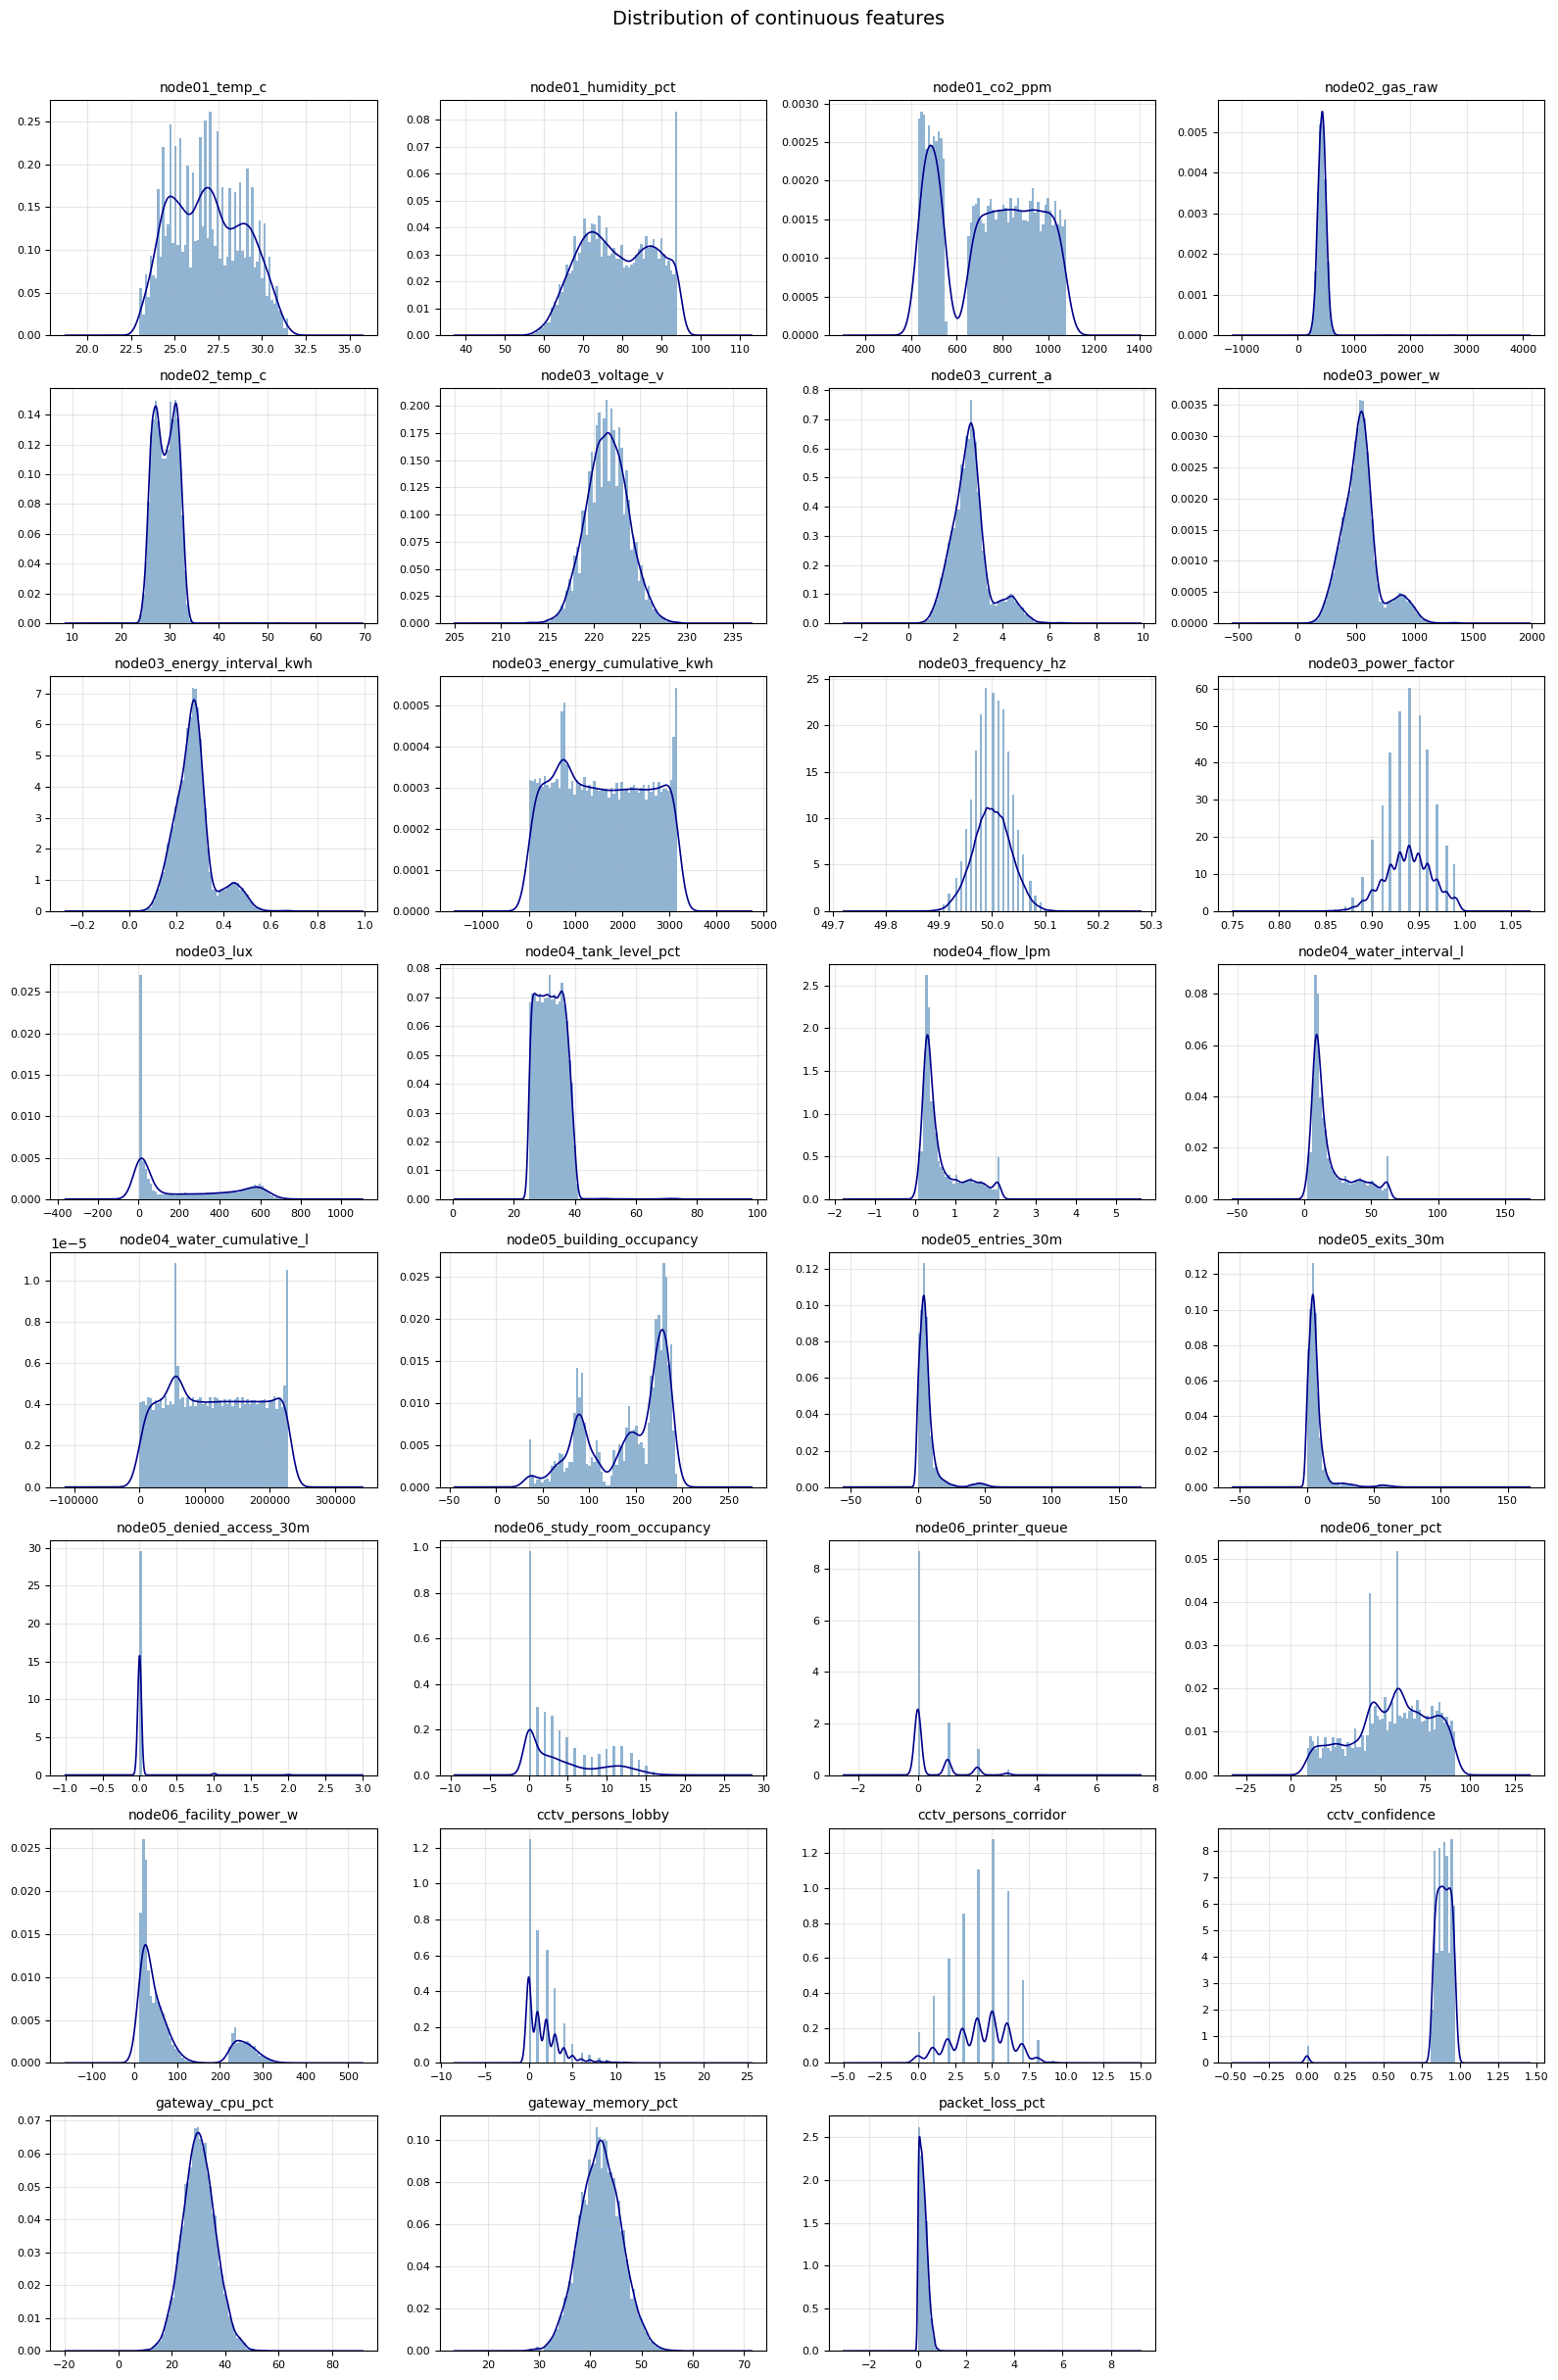

✓ Saved to /content/figures/fig_01_distributions.png


In [8]:
cont_cols = col_groups["feature_continuous"]
n_cols_plot = 4
n_rows_plot = int(np.ceil(len(cont_cols) / n_cols_plot))

fig, axes = plt.subplots(n_rows_plot, n_cols_plot, figsize=(16, n_rows_plot * 3))
axes = axes.flatten()

for i, col in enumerate(cont_cols):
    ax = axes[i]
    ax.hist(df[col], bins=60, density=True, alpha=0.6, color="steelblue", edgecolor="none")
    df[col].plot.kde(ax=ax, color="darkblue", linewidth=1.2)
    ax.set_title(col, fontsize=10)
    ax.set_ylabel("")
    ax.tick_params(labelsize=8)

# Hide unused axes
for j in range(len(cont_cols), len(axes)):
    axes[j].set_visible(False)

fig.suptitle("Distribution of continuous features", fontsize=14, y=1.01)
fig.tight_layout()
fig.savefig(f"{FIGURE_DIR}/fig_01_distributions.png", bbox_inches="tight")
plt.show()

print(f"✓ Saved to {FIGURE_DIR}/fig_01_distributions.png")

### Temporal patterns — diurnal and weekly cycles
**Tujuan**: Mengidentifikasi pola diurnal (jam) dan mingguan pada fitur-fitur kunci. Pola temporal yang kuat menjustifikasi penggunaan BiLSTM-AE.
**Input**: `df`.
**Output**: Heatmap pola jam × hari untuk fitur representatif, disimpan sebagai `fig_02_temporal_patterns.png`.


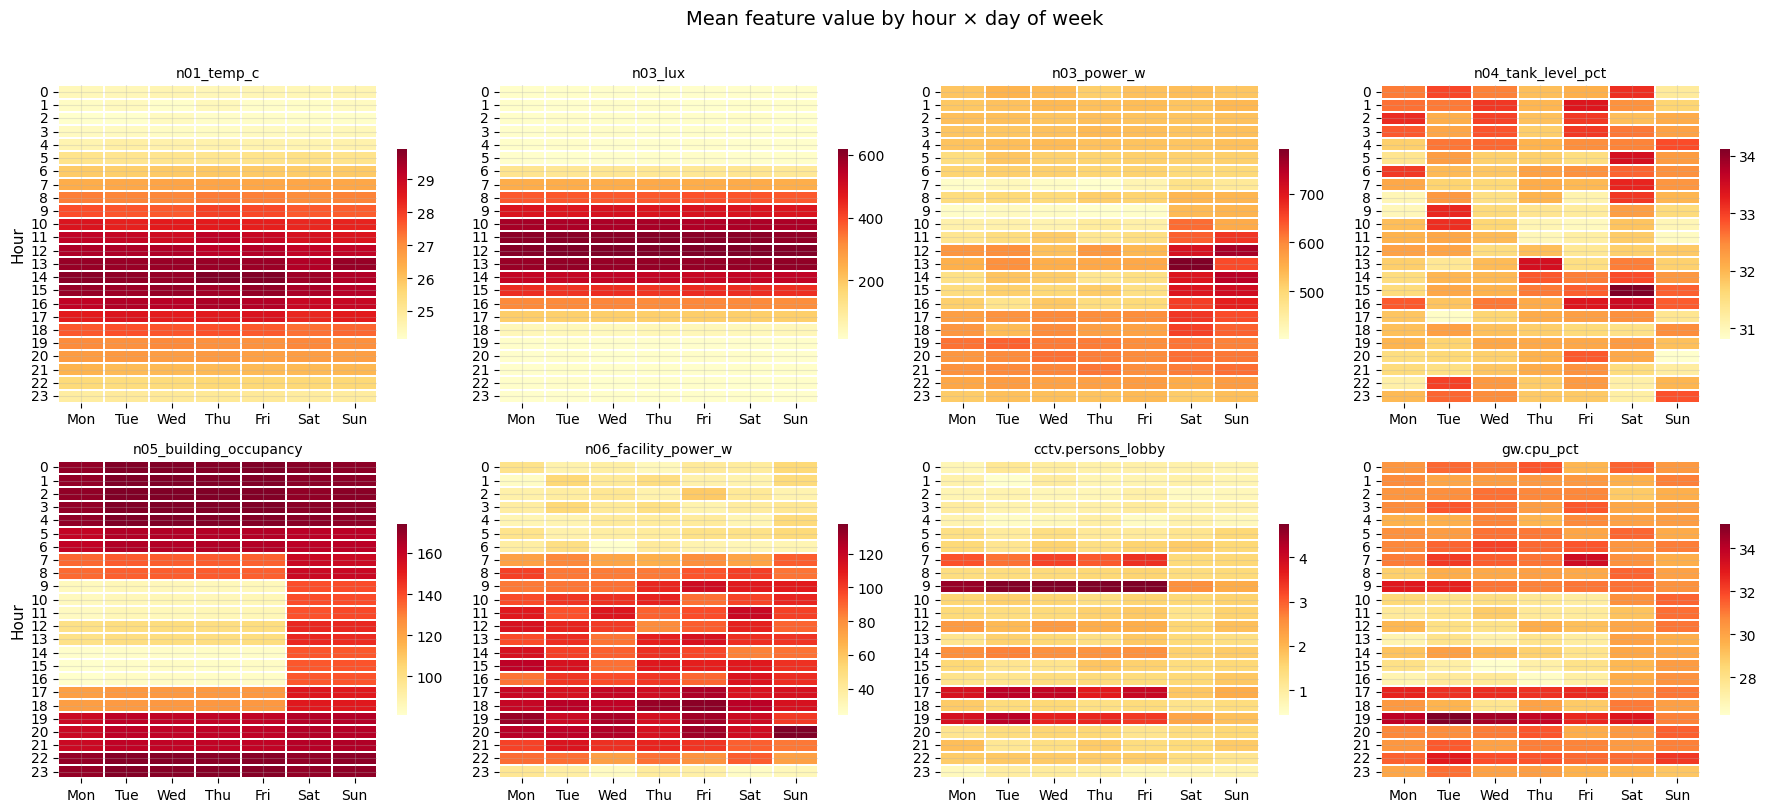

✓ Saved to /content/figures/fig_02_temporal_patterns.png


In [9]:
df["hour"] = df[TIMESTAMP_COL].dt.hour
df["dow"] = df[TIMESTAMP_COL].dt.dayofweek  # 0=Monday
df["dow_name"] = df[TIMESTAMP_COL].dt.day_name()

# Select representative features (one per node subsystem)
temporal_features = [
    "node01_temp_c",
    "node03_lux",
    "node03_power_w",
    "node04_tank_level_pct",
    "node05_building_occupancy",
    "node06_facility_power_w",
    "cctv_persons_lobby",
    "gateway_cpu_pct",
]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

dow_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

for i, col in enumerate(temporal_features):
    pivot = df.pivot_table(values=col, index="hour", columns="dow_name", aggfunc="mean")
    pivot = pivot[dow_order]

    sns.heatmap(
        pivot,
        ax=axes[i],
        cmap="YlOrRd",
        xticklabels=[d[:3] for d in dow_order],
        yticklabels=True,
        cbar_kws={"shrink": 0.6, "label": ""},
        linewidths=0.1,
        linecolor="white",
    )
    axes[i].set_title(col.replace("node0", "n0").replace("cctv_", "cctv.").replace("gateway_", "gw."), fontsize=10)
    axes[i].set_ylabel("Hour" if i % 4 == 0 else "")
    axes[i].set_xlabel("")

fig.suptitle("Mean feature value by hour × day of week", fontsize=14, y=1.01)
fig.tight_layout()
fig.savefig(f"{FIGURE_DIR}/fig_02_temporal_patterns.png", bbox_inches="tight")
plt.show()

print(f"✓ Saved to {FIGURE_DIR}/fig_02_temporal_patterns.png")

### Autocorrelation analysis
**Tujuan**: Mengukur autokorelasi pada lag kritis (1 step=30min, 2 step=1h, 48 step=24h, 336 step=7 hari) untuk mengkuantifikasi kekuatan dependensi temporal dan menjustifikasi pemilihan window size BiLSTM-AE.
**Input**: `df`, fitur kontinu kunci.
**Output**: Tabel autokorelasi dan plot ACF, disimpan sebagai `fig_03_autocorrelation.png`.

In [10]:
from statsmodels.tsa.stattools import acf

key_features = [
    "node01_temp_c", "node01_humidity_pct", "node01_co2_ppm",
    "node02_gas_raw", "node02_temp_c",
    "node03_power_w", "node03_lux",
    "node04_tank_level_pct", "node04_flow_lpm",
    "node05_building_occupancy", "node05_entries_30m",
    "node06_facility_power_w", "node06_toner_pct",
    "cctv_persons_lobby", "cctv_persons_corridor",
    "gateway_cpu_pct", "gateway_memory_pct",
    "packet_loss_pct",
]

lags_of_interest = {
    "lag_1 (30m)": 1,
    "lag_2 (1h)": 2,
    "lag_6 (3h)": 6,
    "lag_48 (24h)": 48,
    "lag_336 (7d)": 336,
}

acf_results = []
for col in key_features:
    series = df[col].values
    acf_vals = acf(series, nlags=340, fft=True)
    row = {"feature": col}
    for name, lag in lags_of_interest.items():
        row[name] = round(acf_vals[lag], 3)
    acf_results.append(row)

acf_df = pd.DataFrame(acf_results).set_index("feature")
print(acf_df.to_string())

# Classify temporal strength
print("\n=== Temporal dependency strength ===")
for _, row in acf_df.iterrows():
    lag24 = row["lag_48 (24h)"]
    if lag24 > 0.7:
        strength = "STRONG diurnal"
    elif lag24 > 0.3:
        strength = "MODERATE diurnal"
    else:
        strength = "WEAK diurnal"
    print(f"  {row.name}: {strength} (24h ACF = {lag24})")

# === Assertion ===
assert len(acf_df) == len(key_features), "Missing ACF results"
print(f"\n✓ ACF computed for {len(key_features)} features.")

                           lag_1 (30m)  lag_2 (1h)  lag_6 (3h)  lag_48 (24h)  lag_336 (7d)
feature                                                                                   
node01_temp_c                    0.892       0.869       0.642         0.896         0.869
node01_humidity_pct              0.897       0.870       0.654         0.887         0.809
node01_co2_ppm                   0.277       0.290       0.191         0.269         0.240
node02_gas_raw                   0.001       0.012       0.011        -0.001        -0.005
node02_temp_c                    0.866       0.845       0.627         0.869         0.847
node03_power_w                   0.375       0.350       0.280         0.316         0.270
node03_lux                       0.973       0.936       0.604         0.982         0.957
node04_tank_level_pct            0.648       0.393       0.051         0.028        -0.032
node04_flow_lpm                  0.884       0.692      -0.219         0.941         0.892

### Inter-feature correlation & multicollinearity
**Tujuan**: Mengidentifikasi korelasi kuat antar fitur untuk mendeteksi redundansi dan multikolinearitas. Pasangan dengan korelasi >0.85 perlu dipertimbangkan untuk di-drop atau di-combine.
**Input**: `df`, `feature_continuous`.
**Output**: Correlation heatmap dan daftar pasangan berkorelasi tinggi, disimpan sebagai `fig_04_correlation_matrix.png`.

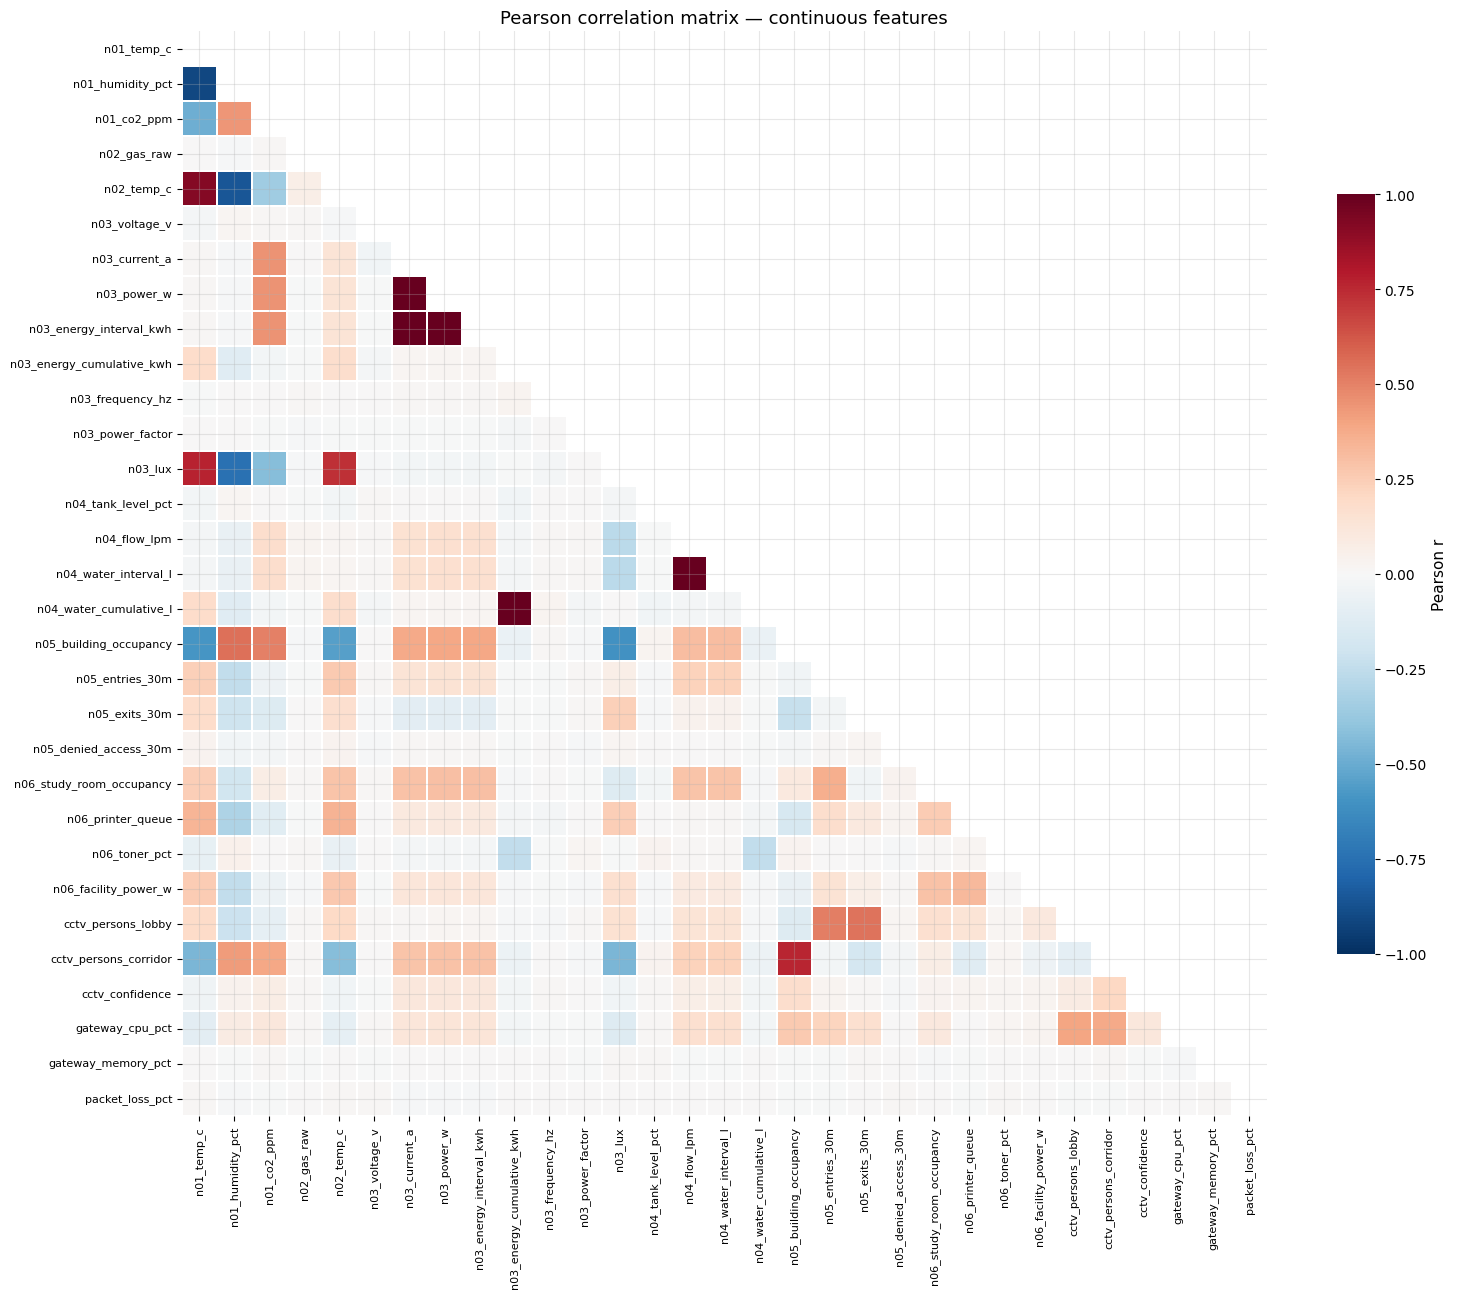

Pairs with |r| > 0.80 (8 found):

                   feature_1                  feature_2  pearson_r
node03_energy_cumulative_kwh  node04_water_cumulative_l      1.000
             node04_flow_lpm    node04_water_interval_l      1.000
              node03_power_w node03_energy_interval_kwh      1.000
            node03_current_a             node03_power_w      0.994
            node03_current_a node03_energy_interval_kwh      0.994
               node01_temp_c              node02_temp_c      0.921
               node01_temp_c        node01_humidity_pct     -0.907
         node01_humidity_pct              node02_temp_c     -0.856

✓ Saved to /content/figures/fig_04_correlation_matrix.png


In [11]:
corr = df[col_groups["feature_continuous"]].corr()

# Plot heatmap
fig, ax = plt.subplots(figsize=(16, 13))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(
    corr,
    mask=mask,
    cmap="RdBu_r",
    center=0,
    vmin=-1, vmax=1,
    ax=ax,
    square=True,
    linewidths=0.3,
    cbar_kws={"shrink": 0.7, "label": "Pearson r"},
    xticklabels=[c.replace("node0", "n0") for c in col_groups["feature_continuous"]],
    yticklabels=[c.replace("node0", "n0") for c in col_groups["feature_continuous"]],
)
ax.tick_params(labelsize=8)
ax.set_title("Pearson correlation matrix — continuous features", fontsize=13)
fig.tight_layout()
fig.savefig(f"{FIGURE_DIR}/fig_04_correlation_matrix.png", bbox_inches="tight")
plt.show()

# Extract high-correlation pairs
high_corr_pairs = []
for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        r = corr.iloc[i, j]
        if abs(r) > 0.80:
            high_corr_pairs.append({
                "feature_1": corr.columns[i],
                "feature_2": corr.columns[j],
                "pearson_r": round(r, 3),
            })

high_corr_df = pd.DataFrame(high_corr_pairs).sort_values("pearson_r", key=abs, ascending=False)
print(f"Pairs with |r| > 0.80 ({len(high_corr_df)} found):\n")
print(high_corr_df.to_string(index=False))

print(f"\n✓ Saved to {FIGURE_DIR}/fig_04_correlation_matrix.png")

### Anomaly proxy characterization
**Tujuan**: Menganalisis secara mendalam kolom `is_anomaly_proxy` dan `anomaly_severity_proxy` untuk memahami komposisi anomali, node mana yang menjadi trigger, dan membangun tiered anomaly taxonomy.
**Input**: `df`, label columns.
**Output**: Breakdown anomali per node, per severity, dan analisis cross-node co-occurrence.

In [12]:
print("=== Anomaly proxy distribution ===")
print(df["is_anomaly_proxy"].value_counts().to_frame("count").assign(
    pct=lambda x: (x["count"] / len(df) * 100).round(1)
))
print()

print("=== Severity distribution ===")
print(df["anomaly_severity_proxy"].value_counts().to_frame("count").assign(
    pct=lambda x: (x["count"] / len(df) * 100).round(1)
))
print()

# Which nodes trigger anomaly?
anom = df[df["is_anomaly_proxy"] == 1].copy()
log_cols = [c for c in df.columns if c.endswith("_log_level") and c != "command_log_level"]

print(f"=== Node-level triggers in anomaly rows (n={len(anom)}) ===")
trigger_counts = {}
for c in log_cols:
    node_name = c.replace("_log_level", "")
    n_triggered = (anom[c] != "INFO").sum()
    trigger_counts[node_name] = n_triggered
    if n_triggered > 0:
        breakdown = anom[c].value_counts().to_dict()
        print(f"  {node_name}: {n_triggered} triggered ({n_triggered/len(anom)*100:.1f}%) — {breakdown}")

print()

# How many nodes trigger simultaneously?
anom["n_triggered_nodes"] = sum((anom[c] != "INFO").astype(int) for c in log_cols)
print("=== Simultaneous node triggers ===")
print(anom["n_triggered_nodes"].value_counts().sort_index().to_frame("count").assign(
    pct=lambda x: (x["count"] / len(anom) * 100).round(1)
))
print()

# Tiered taxonomy
print("=== Proposed tiered anomaly taxonomy ===")
critical_events = ["FIRE_EVENT_CONFIRMED", "LEAK_DETECTED_VALVE_CLOSED",
                   "PANIC_BUTTON_ACTIVATED", "EMERGENCY_ACCESS_MODE",
                   "RESTRICTED_AREA_INTRUSION", "VISUAL_FIRE_DETECTED"]

event_cols = [c for c in df.columns if c.endswith("_event") and c != "command_event"]

# Tag each row
def classify_severity(row):
    for ec in event_cols:
        if row[ec] in critical_events:
            return "CRITICAL"
    # Check multi-node warning
    n_warning = sum(1 for c in log_cols if row[c] != "INFO")
    if n_warning >= 2:
        return "MULTI_NODE_WARNING"
    if n_warning == 1:
        return "SINGLE_NODE_WARNING"
    return "NORMAL"

df["anomaly_tier"] = df.apply(classify_severity, axis=1)

print(df["anomaly_tier"].value_counts().to_frame("count").assign(
    pct=lambda x: (x["count"] / len(df) * 100).round(1)
))
print()

# Cross-validate with proxy
print("=== Tier vs is_anomaly_proxy ===")
print(pd.crosstab(df["anomaly_tier"], df["is_anomaly_proxy"], margins=True))

# === Assertion ===
assert df["anomaly_tier"].notna().all(), "NaN in anomaly_tier"
print("\n✓ Anomaly taxonomy created.")

=== Anomaly proxy distribution ===
                  count   pct
is_anomaly_proxy             
0                  6684  57.5
1                  4932  42.5

=== Severity distribution ===
                        count   pct
anomaly_severity_proxy             
NORMAL                   6684  57.5
WARNING                  4923  42.4
CRITICAL                    9   0.1

=== Node-level triggers in anomaly rows (n=4932) ===
  node01: 390 triggered (7.9%) — {'INFO': 4542, 'WARNING': 390}
  node02: 13 triggered (0.3%) — {'INFO': 4919, 'WARNING': 8, 'CRITICAL': 5}
  node03: 171 triggered (3.5%) — {'INFO': 4761, 'WARNING': 171}
  node04: 4145 triggered (84.0%) — {'WARNING': 4141, 'INFO': 787, 'CRITICAL': 4}
  node05: 171 triggered (3.5%) — {'INFO': 4761, 'WARNING': 168, 'CRITICAL': 3}
  node06: 501 triggered (10.2%) — {'INFO': 4431, 'WARNING': 501}
  cctv: 8 triggered (0.2%) — {'INFO': 4924, 'WARNING': 5, 'CRITICAL': 3}

=== Simultaneous node triggers ===
                   count   pct
n_triggered

### Feature behavior across anomaly tiers
**Tujuan**: Membandingkan distribusi fitur kontinu pada setiap tier anomali untuk mengidentifikasi fitur mana yang paling diskriminatif — ini menentukan mana yang paling berguna untuk deteksi.
**Input**: `df`, `anomaly_tier`, `feature_continuous`.
**Output**: Tabel perbandingan mean per tier dan visualisasi fitur paling diskriminatif, disimpan sebagai `fig_05_feature_by_tier.png`.

=== 5 inconsistent rows (NORMAL tier but proxy=1) ===
               timestamp command_log_level      command_event   mqtt_status
2106 2025-12-14 21:00:00           WARNING  MQTT_RECONNECTING  RECONNECTING
3042 2026-01-03 09:00:00           WARNING  MQTT_RECONNECTING  RECONNECTING
3062 2026-01-03 19:00:00           WARNING  MQTT_RECONNECTING  RECONNECTING
7460 2026-04-05 10:00:00           WARNING  MQTT_RECONNECTING  RECONNECTING
8282 2026-04-22 13:00:00           WARNING  MQTT_RECONNECTING  RECONNECTING

=== Top discriminative features (|effect size| > 0.5) ===

SINGLE_NODE_WARNING (4475 rows):
  ↓ node04_tank_level_pct: effect size = -1.87

MULTI_NODE_WARNING (438 rows):
  ↓ node04_tank_level_pct: effect size = -2.07
  ↓ node06_toner_pct: effect size = -1.1
  ↑ node01_temp_c: effect size = 0.99
  ↑ node02_temp_c: effect size = 0.86
  ↓ node01_humidity_pct: effect size = -0.79
  ↑ node03_lux: effect size = 0.59

CRITICAL (14 rows):
  ↑ node02_gas_raw: effect size = 6.67
  ↑ node02_tem

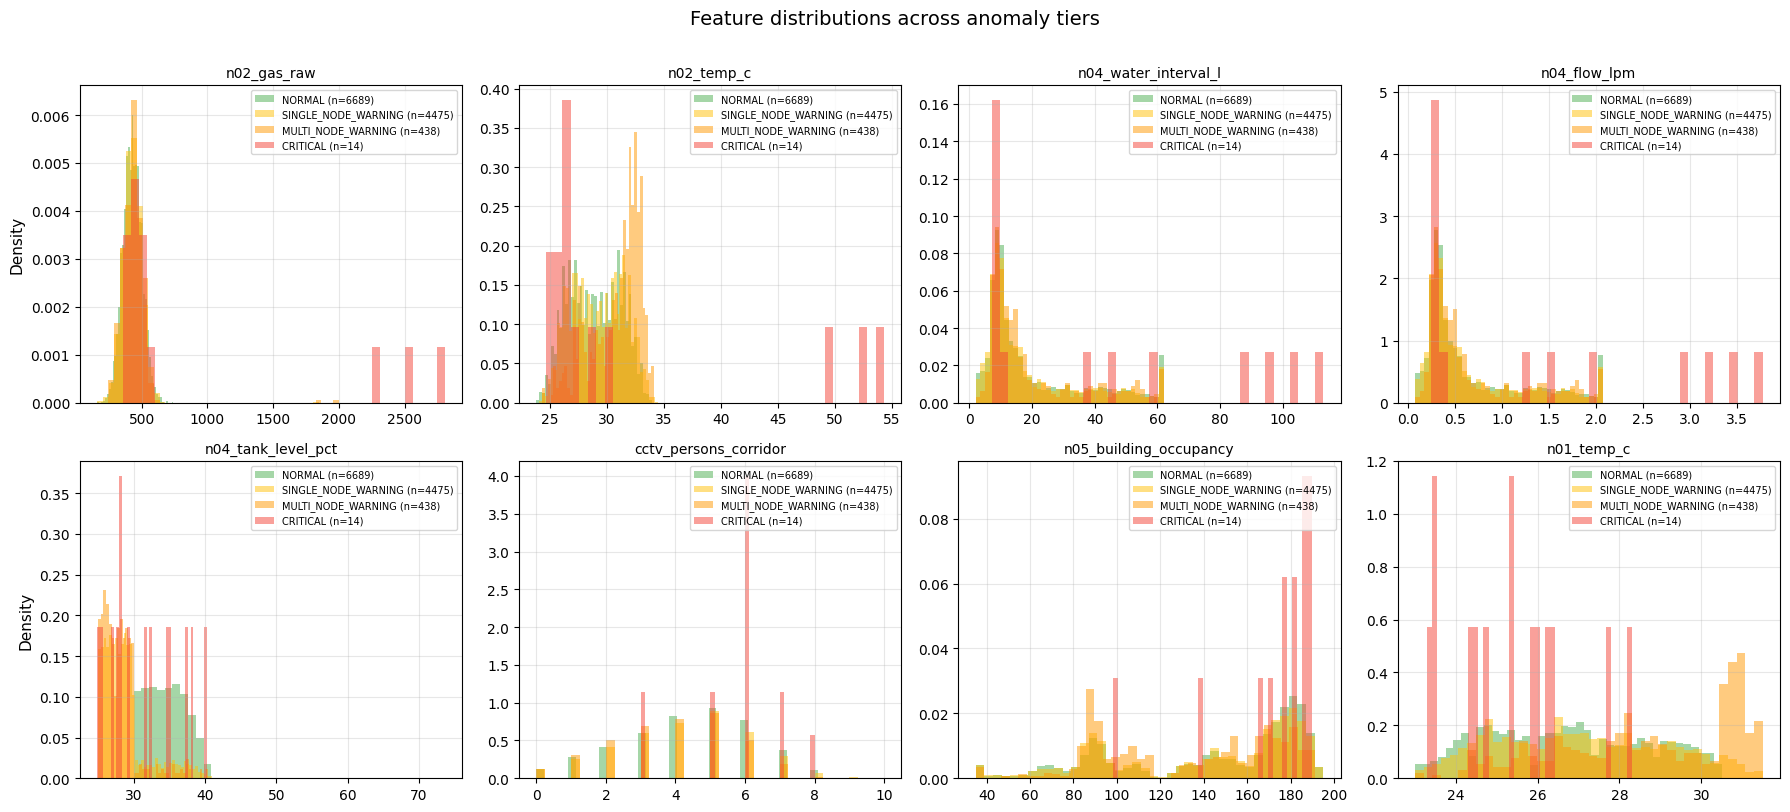

✓ Saved to /content/figures/fig_05_feature_by_tier.png


In [13]:
# Investigate the 5 inconsistent rows first
inconsistent = df[(df["anomaly_tier"] == "NORMAL") & (df["is_anomaly_proxy"] == 1)]
print(f"=== 5 inconsistent rows (NORMAL tier but proxy=1) ===")
print(inconsistent[["timestamp", "command_log_level", "command_event", "mqtt_status"]].to_string())
print()

# Mean per tier for continuous features
tier_order = ["NORMAL", "SINGLE_NODE_WARNING", "MULTI_NODE_WARNING", "CRITICAL"]
tier_means = df.groupby("anomaly_tier")[col_groups["feature_continuous"]].mean().reindex(tier_order)

# Calculate effect size: (tier_mean - normal_mean) / normal_std
normal_mean = tier_means.loc["NORMAL"]
normal_std = df[df["anomaly_tier"] == "NORMAL"][col_groups["feature_continuous"]].std()

effect_sizes = pd.DataFrame(index=tier_order[1:])
for col in col_groups["feature_continuous"]:
    for tier in tier_order[1:]:
        if normal_std[col] > 0:
            effect_sizes.loc[tier, col] = round(
                (tier_means.loc[tier, col] - normal_mean[col]) / normal_std[col], 2
            )

# Top discriminative features per tier
print("=== Top discriminative features (|effect size| > 0.5) ===\n")
for tier in tier_order[1:]:
    row = effect_sizes.loc[tier].abs().sort_values(ascending=False)
    top = row[row > 0.5]
    print(f"{tier} ({df[df['anomaly_tier']==tier].shape[0]} rows):")
    for feat, es in top.items():
        direction = "↑" if effect_sizes.loc[tier, feat] > 0 else "↓"
        print(f"  {direction} {feat}: effect size = {effect_sizes.loc[tier, feat]}")
    print()

# Plot top 8 most discriminative features
top_features = effect_sizes.loc["CRITICAL"].abs().sort_values(ascending=False).head(8).index.tolist()

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

colors = {"NORMAL": "#4CAF50", "SINGLE_NODE_WARNING": "#FFC107",
          "MULTI_NODE_WARNING": "#FF9800", "CRITICAL": "#F44336"}

for i, col in enumerate(top_features):
    ax = axes[i]
    for tier in tier_order:
        subset = df[df["anomaly_tier"] == tier][col]
        ax.hist(subset, bins=40, alpha=0.5, density=True,
                label=f"{tier} (n={len(subset)})", color=colors[tier], edgecolor="none")
    ax.set_title(col.replace("node0", "n0"), fontsize=10)
    ax.legend(fontsize=7, loc="upper right")
    ax.set_ylabel("Density" if i % 4 == 0 else "")

fig.suptitle("Feature distributions across anomaly tiers", fontsize=14, y=1.01)
fig.tight_layout()
fig.savefig(f"{FIGURE_DIR}/fig_05_feature_by_tier.png", bbox_inches="tight")
plt.show()

print(f"✓ Saved to {FIGURE_DIR}/fig_05_feature_by_tier.png")

### Temporal distribution of anomalies
**Tujuan**: Menganalisis kapan anomali terjadi (per jam, per bulan, per hari) untuk memahami apakah ada pola temporal pada kejadian anomali dan implikasinya terhadap train/test split.
**Input**: `df`, `anomaly_tier`.
**Output**: Visualisasi distribusi temporal anomali, disimpan sebagai `fig_06_anomaly_temporal.png`.

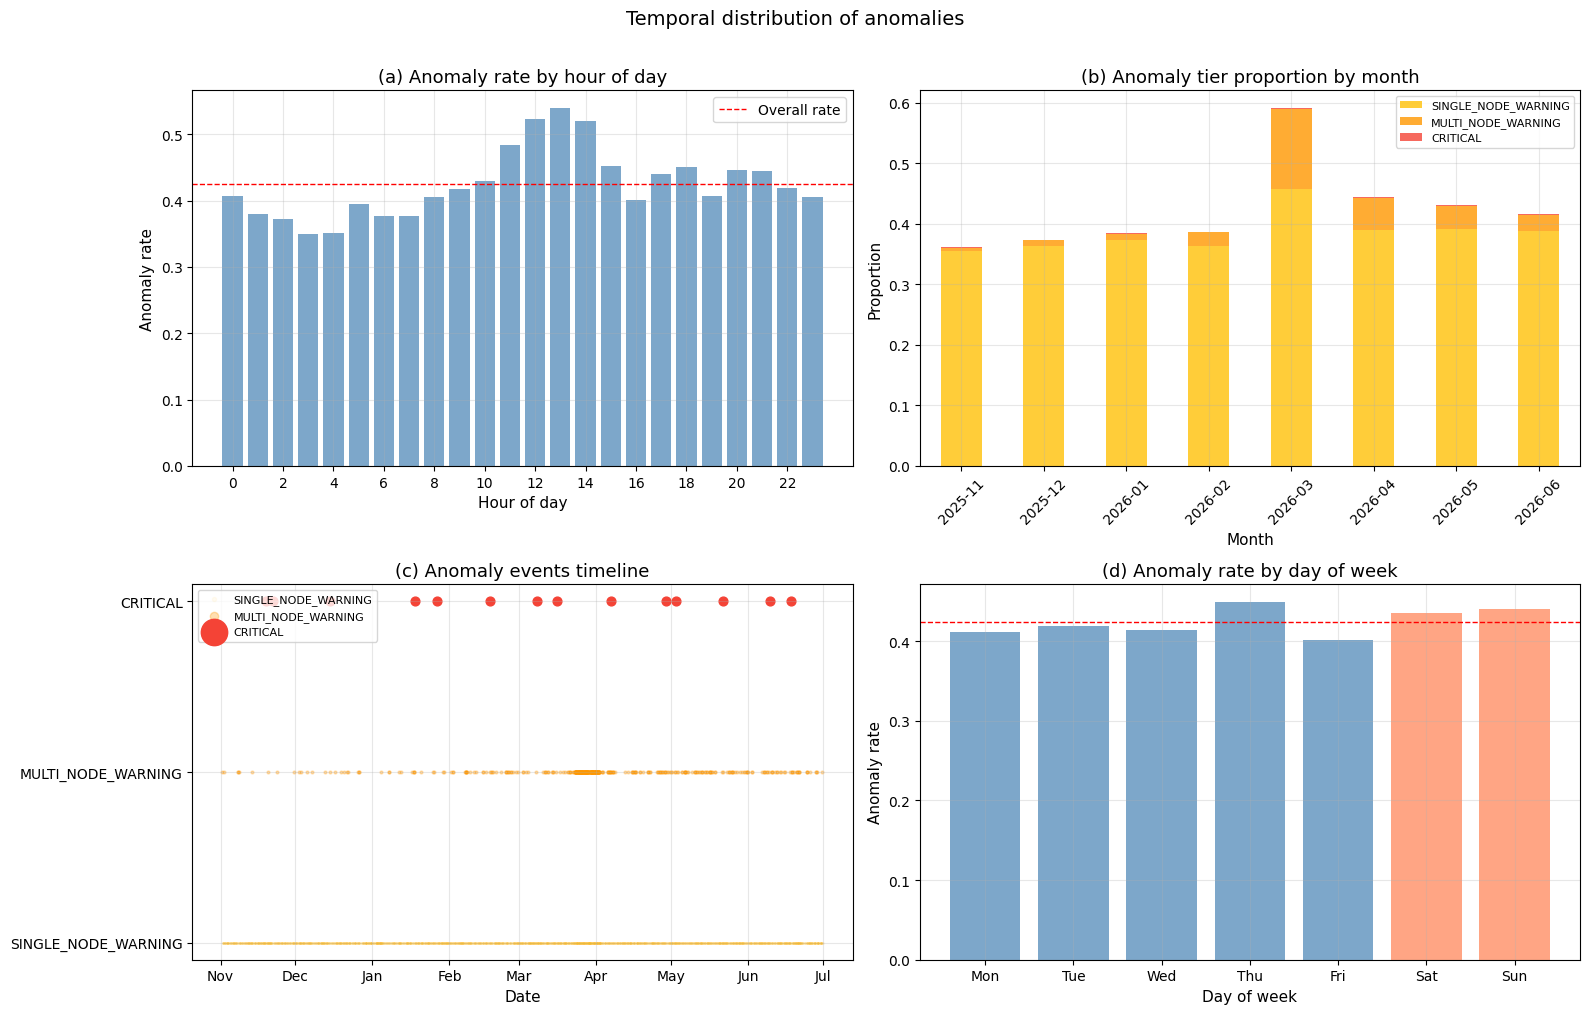

✓ Saved to /content/figures/fig_06_anomaly_temporal.png


In [14]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

tier_order = ["NORMAL", "SINGLE_NODE_WARNING", "MULTI_NODE_WARNING", "CRITICAL"]
colors = {"NORMAL": "#4CAF50", "SINGLE_NODE_WARNING": "#FFC107",
          "MULTI_NODE_WARNING": "#FF9800", "CRITICAL": "#F44336"}

# (a) Anomaly rate by hour
ax = axes[0, 0]
hourly_rate = df.groupby("hour")["is_anomaly_proxy"].mean()
ax.bar(hourly_rate.index, hourly_rate.values, color="steelblue", alpha=0.7)
ax.set_xlabel("Hour of day")
ax.set_ylabel("Anomaly rate")
ax.set_title("(a) Anomaly rate by hour of day")
ax.set_xticks(range(0, 24, 2))
ax.axhline(y=df["is_anomaly_proxy"].mean(), color="red", linestyle="--", linewidth=1, label="Overall rate")
ax.legend()

# (b) Anomaly tier by month
ax = axes[0, 1]
df["month"] = df[TIMESTAMP_COL].dt.to_period("M").astype(str)
month_tier = pd.crosstab(df["month"], df["anomaly_tier"], normalize="index")[tier_order[1:]]
month_tier.plot(kind="bar", stacked=True, ax=ax, color=[colors[t] for t in tier_order[1:]], alpha=0.8)
ax.set_xlabel("Month")
ax.set_ylabel("Proportion")
ax.set_title("(b) Anomaly tier proportion by month")
ax.legend(fontsize=8, loc="upper right")
ax.tick_params(axis="x", rotation=45)

# (c) Timeline of CRITICAL events
ax = axes[1, 0]
for tier in ["SINGLE_NODE_WARNING", "MULTI_NODE_WARNING", "CRITICAL"]:
    subset = df[df["anomaly_tier"] == tier]
    marker_size = {"SINGLE_NODE_WARNING": 1, "MULTI_NODE_WARNING": 4, "CRITICAL": 40}
    alpha = {"SINGLE_NODE_WARNING": 0.05, "MULTI_NODE_WARNING": 0.3, "CRITICAL": 1.0}
    ax.scatter(subset[TIMESTAMP_COL], subset["anomaly_tier"],
               s=marker_size[tier], alpha=alpha[tier], color=colors[tier], label=tier)
ax.set_xlabel("Date")
ax.set_ylabel("")
ax.set_title("(c) Anomaly events timeline")
ax.legend(fontsize=8, markerscale=3)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))

# (d) Anomaly rate by day of week
ax = axes[1, 1]
dow_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
dow_rate = df.groupby("dow")["is_anomaly_proxy"].mean()
bar_colors = ["steelblue"] * 5 + ["coral", "coral"]
ax.bar(range(7), dow_rate.values, color=bar_colors, alpha=0.7)
ax.set_xticks(range(7))
ax.set_xticklabels(dow_names)
ax.set_xlabel("Day of week")
ax.set_ylabel("Anomaly rate")
ax.set_title("(d) Anomaly rate by day of week")
ax.axhline(y=df["is_anomaly_proxy"].mean(), color="red", linestyle="--", linewidth=1)

fig.suptitle("Temporal distribution of anomalies", fontsize=14, y=1.01)
fig.tight_layout()
fig.savefig(f"{FIGURE_DIR}/fig_06_anomaly_temporal.png", bbox_inches="tight")
plt.show()

print(f"✓ Saved to {FIGURE_DIR}/fig_06_anomaly_temporal.png")

### EDA summary & feature engineering decisions
**Tujuan**: Merangkum seluruh temuan EDA dan mendokumentasikan keputusan feature engineering yang akan diterapkan di notebook berikutnya (`02_preprocessing`).
**Input**: Seluruh temuan EDA di atas.
**Output**: Dokumentasi keputusan terstruktur.

In [15]:
summary = """
╔══════════════════════════════════════════════════════════════════════╗
║                    EDA SUMMARY & DECISIONS                         ║
╚══════════════════════════════════════════════════════════════════════╝

1. DATASET STRUCTURE
   - 11,616 rows × 77 columns, no nulls, no duplicates
   - 30-min interval, 1 Nov 2025 – 30 Jun 2026 (8 months)
   - 7 IoT node categories + system/infra columns

2. COLUMNS TO DROP (before modeling)
   a. Label/leakage (6 cols):
      - is_anomaly_proxy, anomaly_severity_proxy (evaluation only)
      - command_active_alerts, command_log_level,
        command_event, command_workflow (derived from node states)
   b. Cumulative features (2 cols, monotonically increasing):
      - node03_energy_cumulative_kwh
      - node04_water_cumulative_l
   c. Redundant features (3 cols, r > 0.99):
      - node03_energy_interval_kwh (≡ node03_power_w)
      - node04_water_interval_l (≡ node04_flow_lpm)
      - node03_current_a (≡ node03_power_w, r=0.994)

3. TEMPORAL CHARACTERISTICS
   - STRONG diurnal (8 features): temp, humidity, lux, flow,
     occupancy, entries, toner — window=48 justified
   - MODERATE diurnal (3): power_w, cctv_lobby, cctv_corridor
   - WEAK/NO temporal (7): gas_raw, tank_level, facility_power,
     gateway_cpu/mem, packet_loss — better for MEWMA
   - Weekly pattern visible in: power_w, building_occupancy, lux

4. ANOMALY TAXONOMY (4 tiers)
   - NORMAL: 6,689 (57.6%)
   - SINGLE_NODE_WARNING: 4,475 (38.5%) — mostly tank_level
   - MULTI_NODE_WARNING: 438 (3.8%) — temp+humidity+toner+lux
   - CRITICAL: 14 (0.1%) — fire, leak, panic, intrusion
   + 5 MQTT_RECONNECTING events (infra anomaly)

5. FEATURE ENGINEERING (for 02_preprocessing)
   a. Temporal features: hour, day_of_week, is_weekend
   b. Cyclical encoding: sin/cos for hour and dow
   c. Categorical encoding: binary/one-hot for status columns
   d. Scaling: StandardScaler (for MEWMA) and MinMaxScaler
      (for BiLSTM-AE) — fit on training data only
   e. Cross-node correlation preserved (temp1↔temp2, temp↔humidity)
      — valuable for multivariate anomaly detection

6. TRAIN/TEST SPLIT STRATEGY
   - Temporal split (NOT random) — time series structure
   - Train: first 5 months (Nov 2025 – Mar 2026)
   - Test: last 3 months (Apr – Jun 2026)
   - Train on NORMAL data only (unsupervised)
   - Evaluate on all data using proxy labels + taxonomy tiers

7. KEY IMPLICATIONS FOR MODELING
   - BiLSTM-AE: strong temporal features, window=48 (24h)
   - MEWMA: stochastic/event-driven features, mean-shift detection
   - Hybrid fusion justified: complementary feature groups
   - Evaluation: separate metrics per anomaly tier
"""
print(summary)

# Save column lists for next notebook
import json

feature_decisions = {
    "drop_leakage": LABEL_COLS + LEAKAGE_COLS,
    "drop_cumulative": ["node03_energy_cumulative_kwh", "node04_water_cumulative_l"],
    "drop_redundant": ["node03_energy_interval_kwh", "node04_water_interval_l", "node03_current_a"],
    "feature_continuous_final": [
        c for c in col_groups["feature_continuous"]
        if c not in ["node03_energy_cumulative_kwh", "node04_water_cumulative_l",
                     "node03_energy_interval_kwh", "node04_water_interval_l", "node03_current_a"]
    ],
    "feature_binary": col_groups["feature_binary"],
    "feature_categorical": col_groups["feature_categorical"],
    "strong_temporal": ["node01_temp_c", "node01_humidity_pct", "node02_temp_c",
                        "node03_lux", "node04_flow_lpm", "node05_building_occupancy",
                        "node05_entries_30m", "node06_toner_pct"],
    "weak_temporal": ["node02_gas_raw", "node04_tank_level_pct", "node06_facility_power_w",
                      "gateway_cpu_pct", "gateway_memory_pct", "packet_loss_pct"],
}

with open("/content/feature_decisions.json", "w") as f:
    json.dump(feature_decisions, f, indent=2)

print(f"Continuous features after dropping: {len(feature_decisions['feature_continuous_final'])}")
print(f"Binary features: {len(feature_decisions['feature_binary'])}")
print(f"Categorical features: {len(feature_decisions['feature_categorical'])}")
print(f"\n✓ Feature decisions saved to /content/feature_decisions.json")


╔══════════════════════════════════════════════════════════════════════╗
║                    EDA SUMMARY & DECISIONS                         ║
╚══════════════════════════════════════════════════════════════════════╝

1. DATASET STRUCTURE
   - 11,616 rows × 77 columns, no nulls, no duplicates
   - 30-min interval, 1 Nov 2025 – 30 Jun 2026 (8 months)
   - 7 IoT node categories + system/infra columns

2. COLUMNS TO DROP (before modeling)
   a. Label/leakage (6 cols):
      - is_anomaly_proxy, anomaly_severity_proxy (evaluation only)
      - command_active_alerts, command_log_level,
        command_event, command_workflow (derived from node states)
   b. Cumulative features (2 cols, monotonically increasing):
      - node03_energy_cumulative_kwh
      - node04_water_cumulative_l
   c. Redundant features (3 cols, r > 0.99):
      - node03_energy_interval_kwh (≡ node03_power_w)
      - node04_water_interval_l (≡ node04_flow_lpm)
      - node03_current_a (≡ node03_power_w, r=0.994)

3. TEMP